Import Libraries and Load Dataset

In [3]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

df = pd.read_csv("FakeNewsNet.csv")
df.head()

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


Text Preprocessing

In [4]:
df = df.dropna(subset=['title', 'real'])

df['title'] = df['title'].astype(str)

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

df['clean_text'] = df['title'].apply(preprocess_text)

X = df['clean_text']
y = df['real'].astype(int)

display(df[['title', 'clean_text', 'real']].head())

,title,clean_text,real
0,Kandi Burruss Explodes Over Rape Accusation on...,kandi burruss explodes over rape accusation on...,1
1,People's Choice Awards 2018: The best red carp...,peoples choice awards the best red carpet looks,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,sophia bush sends sweet birthday message to on...,1
3,Colombian singer Maluma sparks rumours of inap...,colombian singer maluma sparks rumours of inap...,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,gossip girl years later how upper east siders...,1


Generate Word-Context Co-occurrence Matrix

In [5]:
sentences = [text.split() for text in X]

vectorizer = CountVectorizer(
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None
)

word_matrix = vectorizer.fit_transform(X)

vocabulary = vectorizer.get_feature_names_out()

co_matrix = np.zeros(
    (len(vocabulary), len(vocabulary)),
    dtype=np.float32
)

word_to_id = {
    word: i for i, word in enumerate(vocabulary)
}

window_size = 2

for sentence in sentences:

    for i, word in enumerate(sentence):

        for j in range(
            max(0, i-window_size),
            min(len(sentence), i+window_size+1)
        ):

            if i != j:

                target = word_to_id[word]
                context = word_to_id[sentence[j]]

                co_matrix[target, context] += 1 / abs(i-j)

print("Vocabulary Size:", len(vocabulary))
print("Co-occurrence Matrix Shape:", co_matrix.shape)

Vocabulary Size: 19135
Co-occurrence Matrix Shape: (19135, 19135)


Generate GloVe-Style Word Embeddings

In [6]:
glove_matrix = np.log1p(co_matrix)

if len(vocabulary) >= 3:

    dimensions = min(50, len(vocabulary)-1)

    svd = TruncatedSVD(
        n_components=dimensions,
        random_state=42
    )

    word_embeddings = svd.fit_transform(glove_matrix)

else:
    word_embeddings = glove_matrix

print("GloVe-Style Embedding Shape:", word_embeddings.shape)

GloVe-Style Embedding Shape: (19135, 50)


Find Similar Words Using GloVe-Style Embeddings

In [7]:
def find_similar_words(word, top_n=5):

    if word not in word_to_id:
        print("Word not found in vocabulary")
        return

    word_id = word_to_id[word]

    similarities = cosine_similarity(
        word_embeddings[word_id].reshape(1, -1),
        word_embeddings
    )[0]

    similar_ids = np.argsort(similarities)[::-1]

    results = []

    for idx in similar_ids:

        if idx != word_id:

            results.append({
                'Word': vocabulary[idx],
                'Similarity': round(similarities[idx], 4)
            })

        if len(results) == top_n:
            break

    return pd.DataFrame(results)


find_similar_words("president")

,Word,Similarity
0,clinton,0.8611
1,judge,0.8496
2,white,0.8463
3,obama,0.8459
4,himself,0.8453


Generate Document Embeddings

In [8]:
document_embeddings = []

for sentence in sentences:

    vectors = [
        word_embeddings[word_to_id[word]]
        for word in sentence
        if word in word_to_id
    ]

    if vectors:
        document_embeddings.append(np.mean(vectors, axis=0))
    else:
        document_embeddings.append(
            np.zeros(word_embeddings.shape[1])
        )

document_embeddings = np.array(document_embeddings)

print("Document Embedding Shape:", document_embeddings.shape)

Document Embedding Shape: (23196, 50)


Split Dataset

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    np.arange(len(df)),
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 18556
Testing Samples: 4640


Apply Different Vectorization Techniques

In [10]:
count_vectorizer = CountVectorizer(stop_words='english')

tfidf_vectorizer = TfidfVectorizer(stop_words='english')

fasttext_vectorizer = TfidfVectorizer(
    analyzer='char',
    ngram_range=(3, 5),
    max_features=5000
)

X_count = count_vectorizer.fit_transform(X)

X_tfidf = tfidf_vectorizer.fit_transform(X)

X_fasttext = fasttext_vectorizer.fit_transform(X)

Train and Compare Classification Models

In [11]:
features = {
    'Count Vectorization': X_count,
    'TF-IDF': X_tfidf,
    'FastText-Style Character N-Grams': X_fasttext,
    'GloVe-Style Embeddings': document_embeddings
}

results = []

for name, matrix in features.items():

    X_train_data = matrix[X_train]
    X_test_data = matrix[X_test]

    model = LogisticRegression(max_iter=1000)

    model.fit(X_train_data, y.iloc[X_train])

    predictions = model.predict(X_test_data)

    results.append({
        'Method': name,
        'Accuracy': accuracy_score(y.iloc[X_test], predictions),
        'Precision': precision_score(y.iloc[X_test], predictions, zero_division=0),
        'Recall': recall_score(y.iloc[X_test], predictions, zero_division=0),
        'F1_Score': f1_score(y.iloc[X_test], predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Method,Accuracy,Precision,Recall,F1_Score
0,Count Vectorization,0.8513,0.8717,0.9407,0.9049
1,TF-IDF,0.8418,0.8452,0.9668,0.9019
2,FastText-Style Character N-Grams,0.8347,0.8439,0.9573,0.8970
3,GloVe-Style Embeddings,0.7985,0.8098,0.9567,0.8772


Visualize Performance Comparison

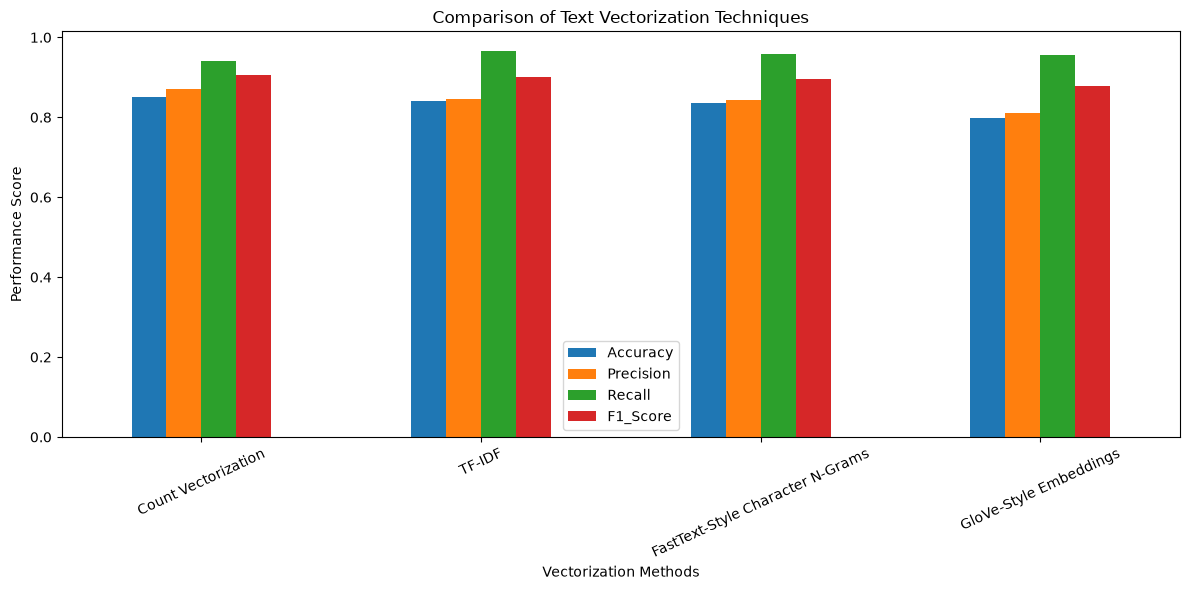

In [12]:
results_df.set_index('Method')[
    ['Accuracy', 'Precision', 'Recall', 'F1_Score']
].plot(kind='bar', figsize=(12, 6))

plt.title("Comparison of Text Vectorization Techniques")
plt.xlabel("Vectorization Methods")
plt.ylabel("Performance Score")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

final results

In [13]:
print("GLOVE AND VECTORIZATION ANALYSIS")

print("\nTotal Articles:", len(df))

print("Vocabulary Size:", len(vocabulary))

print("Embedding Dimensions:", word_embeddings.shape[1])

print("\nClassification Performance:")

display(results_df.round(4))

best_model = results_df.loc[
    results_df['F1_Score'].idxmax()
]

print("\nBest Performing Method:", best_model['Method'])

print("Best F1 Score:", round(best_model['F1_Score'], 4))

GLOVE AND VECTORIZATION ANALYSIS

Total Articles: 23196
Vocabulary Size: 19135
Embedding Dimensions: 50

Classification Performance:


,Method,Accuracy,Precision,Recall,F1_Score
0,Count Vectorization,0.8513,0.8717,0.9407,0.9049
1,TF-IDF,0.8418,0.8452,0.9668,0.9019
2,FastText-Style Character N-Grams,0.8347,0.8439,0.9573,0.8970
3,GloVe-Style Embeddings,0.7985,0.8098,0.9567,0.8772



Best Performing Method: Count Vectorization
Best F1 Score: 0.9049
